# 03 — Preliminary Baseline Models

## Purpose

This notebook provides the preliminary baseline requested in the interim report. It trains Logistic Regression as a simple baseline and Random Forest as the main comparison model for binary and multiclass tasks.

This notebook uses the saved split and preprocessing workflow from Notebook 02. It is not the final leakage study or final dashboard.


In [7]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Paths (works from the repo root or from notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "train_test_network.csv"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in (FIGURES_DIR, METRICS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

In [8]:
df = pd.read_csv(DATA_PATH)
identifier_columns = [c for c in ["src_ip", "dst_ip", "uid", "id", "flow_id", "timestamp"] if c in df.columns]
X = df.drop(columns=["label", "type"] + identifier_columns, errors="ignore")
yb = df["label"].astype(int)
ym = df["type"].astype(str)

X_train, X_temp, yb_train, yb_temp, ym_train, ym_temp = train_test_split(
    X, yb, ym, test_size=0.30, random_state=42, stratify=ym
)
X_val, X_test, yb_val, yb_test, ym_val, ym_test = train_test_split(
    X_temp, yb_temp, ym_temp, test_size=0.50, random_state=42, stratify=ym_temp
)

preprocessor = joblib.load(MODELS_DIR / "preprocessor_main.joblib") if (MODELS_DIR / "preprocessor_main.joblib").exists() else None
if preprocessor is None:
    categorical_columns = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numerical_columns = X_train.select_dtypes(include=np.number).columns.tolist()
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numerical_columns),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True))]), categorical_columns),
    ])

X_train_encoded = preprocessor.fit_transform(X_train)
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)


## 1. Train the binary models

The binary task predicts normal traffic versus attack traffic. Class weighting is applied during training only to reduce the effect of imbalance; validation and test data are not resampled.



 logistic_regression_binary
              precision    recall  f1-score   support

      Normal       0.91      0.92      0.92      7500
      Attack       0.97      0.97      0.97     24157

    accuracy                           0.96     31657
   macro avg       0.94      0.95      0.94     31657
weighted avg       0.96      0.96      0.96     31657



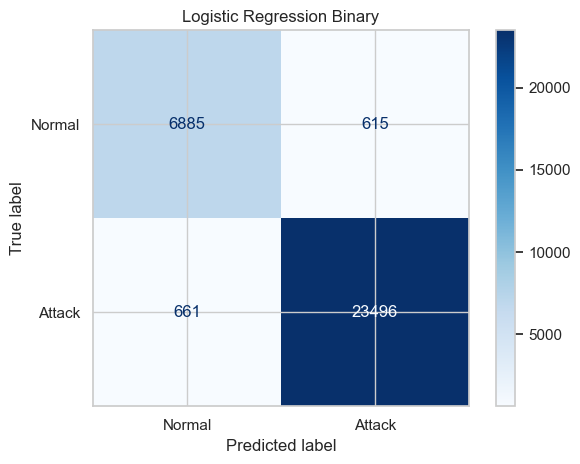


 random_forest_binary
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      7500
      Attack       1.00      1.00      1.00     24157

    accuracy                           1.00     31657
   macro avg       1.00      1.00      1.00     31657
weighted avg       1.00      1.00      1.00     31657



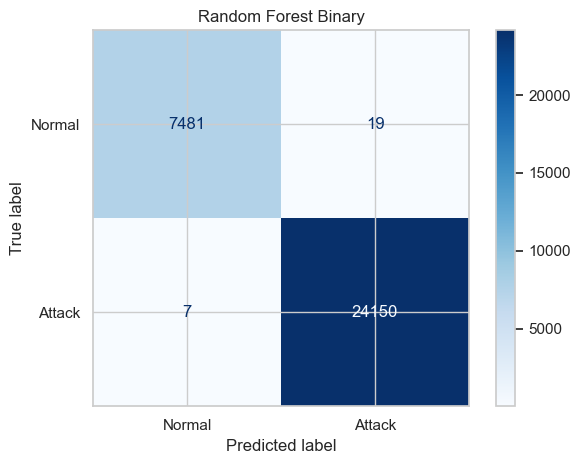

In [9]:
binary_models = {
    "logistic_regression_binary": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "random_forest_binary": RandomForestClassifier(n_estimators=150, class_weight="balanced", random_state=42, n_jobs=-1),
}
results = []
for name, model in binary_models.items():
    model.fit(X_train_encoded, yb_train)
    predictions = model.predict(X_test_encoded)
    results.append({
        "model": name,
        "task": "binary",
        "accuracy": accuracy_score(yb_test, predictions),
        "macro_precision": precision_score(yb_test, predictions, average="macro", zero_division=0),
        "macro_recall": recall_score(yb_test, predictions, average="macro", zero_division=0),
        "macro_f1": f1_score(yb_test, predictions, average="macro", zero_division=0),
    })
    print("\n", name)
    print(classification_report(yb_test, predictions, target_names=["Normal", "Attack"], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(yb_test, predictions, display_labels=["Normal", "Attack"], cmap="Blues")
    plt.title(name.replace("_", " ").title())
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}_confusion_matrix.png", dpi=180)
    plt.show()
    joblib.dump(model, MODELS_DIR / f"{name}.joblib")


## 2. Train the multiclass models

The multiclass task predicts normal, backdoor, DDoS, DoS, injection, password, ransomware, scanning, XSS, or MITM. Macro-F1 is important because it gives each category equal importance, including rare MITM.



 logistic_regression_multiclass
              precision    recall  f1-score   support

    backdoor       0.71      1.00      0.83      3000
        ddos       0.95      0.91      0.93      3000
         dos       0.96      0.96      0.96      3000
   injection       0.76      0.70      0.73      3000
        mitm       0.37      0.94      0.53       157
      normal       1.00      0.85      0.92      7500
    password       0.70      0.56      0.62      3000
  ransomware       0.71      0.90      0.79      3000
    scanning       0.87      0.76      0.81      3000
         xss       0.83      0.88      0.85      3000

    accuracy                           0.84     31657
   macro avg       0.79      0.85      0.80     31657
weighted avg       0.85      0.84      0.84     31657



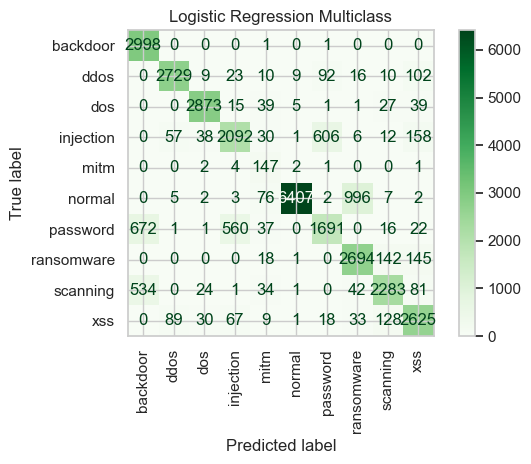


 random_forest_multiclass
              precision    recall  f1-score   support

    backdoor       1.00      1.00      1.00      3000
        ddos       0.99      0.98      0.98      3000
         dos       0.99      0.98      0.98      3000
   injection       0.97      0.97      0.97      3000
        mitm       0.72      0.82      0.77       157
      normal       1.00      1.00      1.00      7500
    password       0.99      0.99      0.99      3000
  ransomware       1.00      1.00      1.00      3000
    scanning       0.98      0.99      0.99      3000
         xss       0.97      0.98      0.98      3000

    accuracy                           0.99     31657
   macro avg       0.96      0.97      0.97     31657
weighted avg       0.99      0.99      0.99     31657



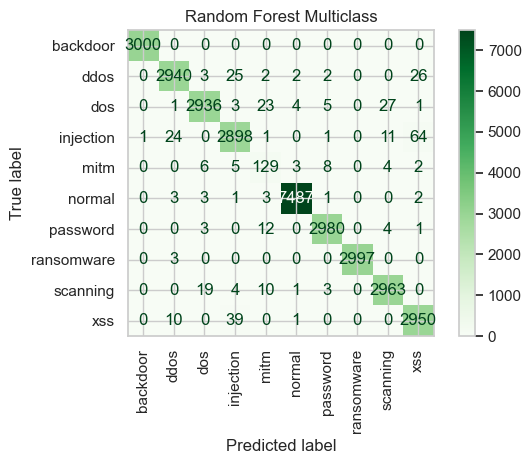

In [10]:
multiclass_models = {
    "logistic_regression_multiclass": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "random_forest_multiclass": RandomForestClassifier(n_estimators=150, class_weight="balanced", random_state=42, n_jobs=-1),
}
for name, model in multiclass_models.items():
    model.fit(X_train_encoded, ym_train)
    predictions = model.predict(X_test_encoded)
    report = classification_report(ym_test, predictions, output_dict=True, zero_division=0)
    results.append({
        "model": name,
        "task": "multiclass",
        "accuracy": accuracy_score(ym_test, predictions),
        "macro_precision": report["macro avg"]["precision"],
        "macro_recall": report["macro avg"]["recall"],
        "macro_f1": report["macro avg"]["f1-score"],
        "mitm_precision": report.get("mitm", {}).get("precision", np.nan),
        "mitm_recall": report.get("mitm", {}).get("recall", np.nan),
        "mitm_f1": report.get("mitm", {}).get("f1-score", np.nan),
    })
    print("\n", name)
    print(classification_report(ym_test, predictions, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(ym_test, predictions, labels=sorted(ym_test.unique()), display_labels=sorted(ym_test.unique()), xticks_rotation="vertical", cmap="Greens")
    plt.title(name.replace("_", " ").title())
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}_confusion_matrix.png", dpi=180)
    plt.show()
    joblib.dump(model, MODELS_DIR / f"{name}.joblib")


In [11]:
model_comparison = pd.DataFrame(results)
display(model_comparison)
model_comparison.to_csv(METRICS_DIR / "model_comparison.csv", index=False)
print("Saved:", METRICS_DIR / "model_comparison.csv")


,model,task,accuracy,macro_precision,macro_recall,macro_f1,mitm_precision,mitm_recall,mitm_f1
0,logistic_regression_binary,binary,0.959693,0.943448,0.945319,0.944379,NaN,NaN,NaN
1,random_forest_binary,binary,0.999179,0.999140,0.998588,0.998864,NaN,NaN,NaN
2,logistic_regression_multiclass,multiclass,0.838330,0.785362,0.845224,0.797474,0.366584,0.936306,0.526882
3,random_forest_multiclass,multiclass,0.988091,0.961031,0.970792,0.965542,0.716667,0.821656,0.765579


Saved: results\metrics\model_comparison.csv


## Preliminary-model report conclusion

Report the actual values from `model_comparison.csv`. Describe Logistic Regression as the baseline and Random Forest as the main model. Treat these results as preliminary because they use a random stratified split. The stricter capture/device/time-disjoint evaluation is still part of the revised work plan.
